# Machine learning · Clustering y validación

Agrupar datos sin etiquetas (k-means), elegir el número de grupos, reducir dimensiones con PCA para visualizarlos y evaluar modelos de forma fiable con validación cruzada y búsqueda de hiperparámetros.

## 1. k-means a mano

Implementar k-means con numpy (asignar cada punto al centro más cercano y mover cada centro a la media de sus puntos hasta que no cambie) y aplicarlo a tres nubes de puntos generadas con `make_blobs`.

inercia: 466.8


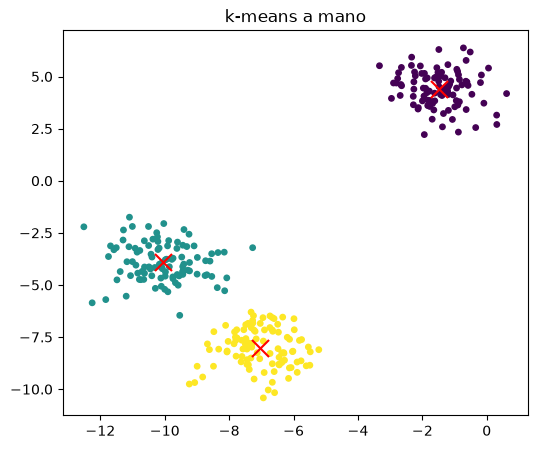

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_digits, load_iris, make_blobs, make_moons

def kmeans(X, k, semilla=0, iteraciones=100):
    rng = np.random.default_rng(semilla)
    centros = X[rng.choice(len(X), k, replace=False)]
    for _ in range(iteraciones):
        distancias = ((X[:, None, :] - centros[None, :, :]) ** 2).sum(axis=2)
        etiquetas = distancias.argmin(axis=1)
        nuevos = np.array([X[etiquetas == j].mean(axis=0) for j in range(k)])
        if np.allclose(nuevos, centros):
            break
        centros = nuevos
    inercia = ((X - centros[etiquetas]) ** 2).sum()
    return etiquetas, centros, inercia

X, y = make_blobs(n_samples=300, centers=3, cluster_std=0.9, random_state=1)
etiquetas, centros, inercia = kmeans(X, 3)
print("inercia:", round(inercia, 1))

fig, eje = plt.subplots(figsize=(6, 5))
eje.scatter(X[:, 0], X[:, 1], c=etiquetas, cmap="viridis", s=15)
eje.scatter(centros[:, 0], centros[:, 1], c="red", marker="x", s=150)
eje.set_title("k-means a mano")
plt.show()

## 2. Comparar con `KMeans`

Comparar el resultado con `sklearn.cluster.KMeans`: la inercia debe ser prácticamente la misma y los grupos deben coincidir salvo por el número que se da a cada uno (medido con `adjusted_rand_score`, que vale 1 si los repartos son iguales).

In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

modelo = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X)
print("inercia sklearn:", round(modelo.inertia_, 1))
print("ARI propio vs sklearn:", adjusted_rand_score(etiquetas, modelo.labels_))
print("ARI frente a los grupos reales:", adjusted_rand_score(y, modelo.labels_))
assert abs(modelo.inertia_ - inercia) / inercia < 0.01

inercia sklearn: 466.8
ARI propio vs sklearn: 1.0
ARI frente a los grupos reales: 0.9899831669528851


## 3. Elegir k: codo y silueta

Probar $k$ de 2 a 8 y dibujar la inercia (método del codo) y el coeficiente de silueta medio para datos con 4 grupos. La silueta es máxima en el número de grupos más natural.

mejor k por silueta: 4


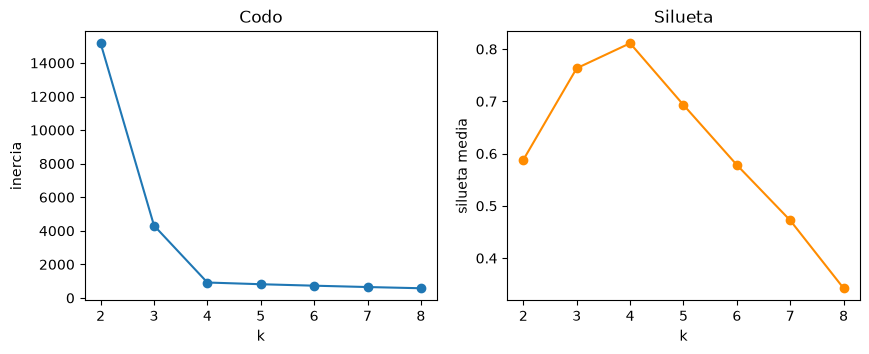

In [3]:
from sklearn.metrics import silhouette_score

X4, _ = make_blobs(n_samples=500, centers=4, cluster_std=1.0, random_state=7)
ks = range(2, 9)
inercias, siluetas = [], []
for k in ks:
    m = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X4)
    inercias.append(m.inertia_)
    siluetas.append(silhouette_score(X4, m.labels_))
mejor = ks[int(np.argmax(siluetas))]
print("mejor k por silueta:", mejor)
assert mejor == 4

fig, (e1, e2) = plt.subplots(1, 2, figsize=(10, 3.5))
e1.plot(ks, inercias, "o-")
e1.set(title="Codo", xlabel="k", ylabel="inercia")
e2.plot(ks, siluetas, "o-", color="darkorange")
e2.set(title="Silueta", xlabel="k", ylabel="silueta media")
plt.show()

## 4. Cuando k-means falla

Aplicar k-means a dos medias lunas (`make_moons`) y ver que corta mal porque supone grupos redondos. Compararlo con `DBSCAN`, que agrupa por densidad.

ARI k-means: 0.274 | ARI DBSCAN: 1.0


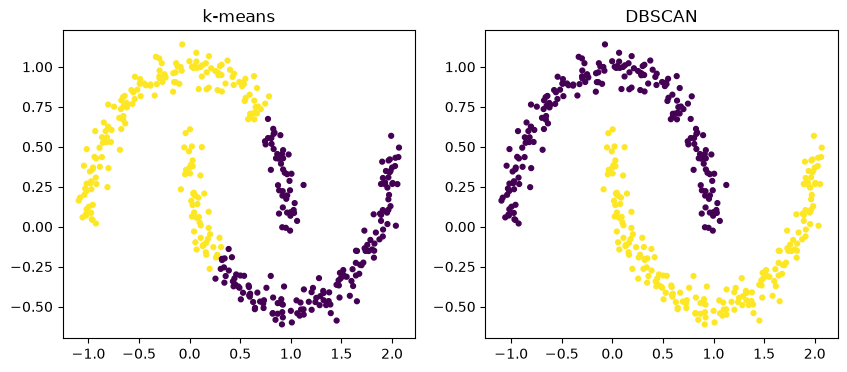

In [4]:
from sklearn.cluster import DBSCAN

Xl, yl = make_moons(n_samples=400, noise=0.06, random_state=0)
km = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(Xl)
db = DBSCAN(eps=0.2, min_samples=5).fit_predict(Xl)
print("ARI k-means:", round(adjusted_rand_score(yl, km), 3), "| ARI DBSCAN:", round(adjusted_rand_score(yl, db), 3))

fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
for eje, etiq, titulo in zip(ejes, (km, db), ("k-means", "DBSCAN")):
    eje.scatter(Xl[:, 0], Xl[:, 1], c=etiq, cmap="viridis", s=12)
    eje.set_title(titulo)
plt.show()

## 5. PCA

Reducir las 64 dimensiones de las imágenes de dígitos a 2 con PCA para dibujarlas, y ver cuánta varianza explican las primeras componentes. Comprobar que PCA a mano (autovectores de la matriz de covarianza) da la misma varianza explicada.

varianza explicada (10 primeras): [0.149 0.136 0.118 0.084 0.058 0.049 0.043 0.037 0.034 0.031]


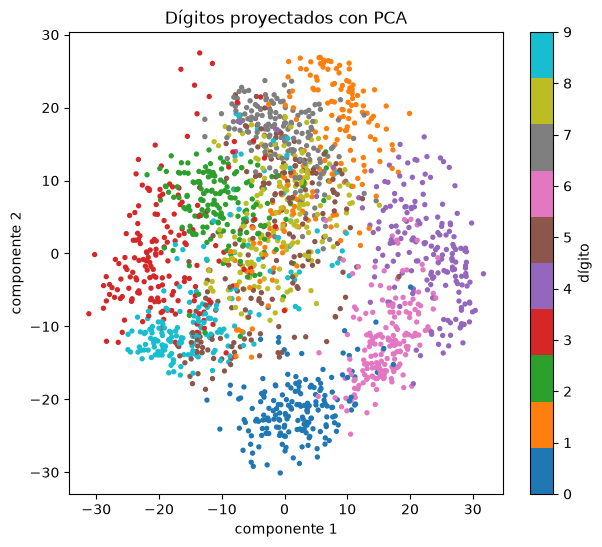

In [5]:
from sklearn.decomposition import PCA

digitos = load_digits()
pca = PCA(n_components=10).fit(digitos.data)
Z = pca.transform(digitos.data)[:, :2]
print("varianza explicada (10 primeras):", pca.explained_variance_ratio_.round(3))

centrados = digitos.data - digitos.data.mean(axis=0)
valores = np.linalg.eigvalsh(np.cov(centrados, rowvar=False))[::-1]
assert np.allclose(valores[:10] / valores.sum(), pca.explained_variance_ratio_)

fig, eje = plt.subplots(figsize=(7, 6))
puntos = eje.scatter(Z[:, 0], Z[:, 1], c=digitos.target, cmap="tab10", s=8)
fig.colorbar(puntos, label="dígito")
eje.set(title="Dígitos proyectados con PCA", xlabel="componente 1", ylabel="componente 2")
plt.show()

## 6. Validación cruzada

Evaluar un clasificador de k vecinos sobre iris con una sola partición train/test con distintas semillas y con validación cruzada de 5 particiones, para ver que una sola partición da una estimación mucho más variable.

In [6]:
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier

iris = load_iris()
modelo = KNeighborsClassifier(n_neighbors=5)

una_particion = []
for semilla in range(20):
    Xtr, Xte, ytr, yte = train_test_split(iris.data, iris.target, test_size=0.2, random_state=semilla)
    una_particion.append(modelo.fit(Xtr, ytr).score(Xte, yte))
cv = cross_val_score(modelo, iris.data, iris.target, cv=5)
print(f"una partición: entre {min(una_particion):.2f} y {max(una_particion):.2f}")
print(f"validación cruzada: {cv.round(3)} -> media {cv.mean():.3f} ± {cv.std():.3f}")

una partición: entre 0.90 y 1.00
validación cruzada: [0.967 1.    0.933 0.967 1.   ] -> media 0.973 ± 0.025


## 7. Validación cruzada a mano

Implementar la validación cruzada de k particiones repartiendo los índices barajados y comprobar que con las mismas particiones (`KFold`) da los mismos resultados que `cross_val_score`.

In [7]:
from sklearn.base import clone
from sklearn.model_selection import KFold

def validacion_cruzada(modelo, X, y, k, semilla):
    indices = np.random.default_rng(semilla).permutation(len(X))
    puntuaciones = []
    for prueba in np.array_split(indices, k):
        entreno = np.setdiff1d(indices, prueba)
        puntuaciones.append(clone(modelo).fit(X[entreno], y[entreno]).score(X[prueba], y[prueba]))
    return np.array(puntuaciones)

print(validacion_cruzada(modelo, iris.data, iris.target, 5, semilla=0).round(3))
kf = KFold(n_splits=5, shuffle=True, random_state=0)
propio = [clone(modelo).fit(iris.data[tr], iris.target[tr]).score(iris.data[te], iris.target[te]) for tr, te in kf.split(iris.data)]
assert np.allclose(propio, cross_val_score(modelo, iris.data, iris.target, cv=kf))

[0.933 1.    0.967 0.967 0.933]


## 8. `GridSearchCV`

Buscar el mejor número de vecinos y tipo de peso para k vecinos sobre los dígitos dentro de un `Pipeline` con escalado, usando `GridSearchCV` con validación cruzada, y evaluar el mejor modelo sobre un conjunto de prueba que no se ha usado en la búsqueda.

mejores parámetros: {'kneighborsclassifier__n_neighbors': 9, 'kneighborsclassifier__weights': 'distance'}
validación cruzada: 0.973 | prueba: 0.964


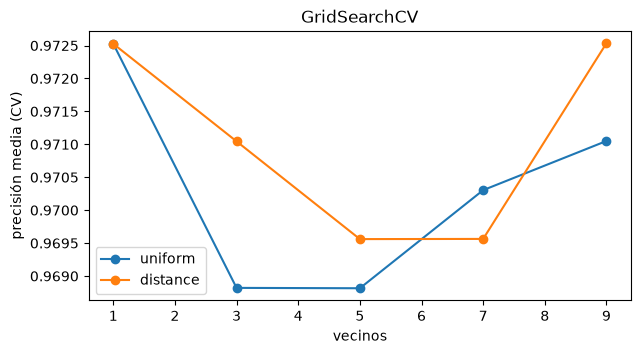

In [8]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

Xtr, Xte, ytr, yte = train_test_split(digitos.data, digitos.target, test_size=0.25, random_state=0, stratify=digitos.target)
tuberia = make_pipeline(StandardScaler(), KNeighborsClassifier())
rejilla = {"kneighborsclassifier__n_neighbors": [1, 3, 5, 7, 9], "kneighborsclassifier__weights": ["uniform", "distance"]}
busqueda = GridSearchCV(tuberia, rejilla, cv=5).fit(Xtr, ytr)
print("mejores parámetros:", busqueda.best_params_)
print(f"validación cruzada: {busqueda.best_score_:.3f} | prueba: {busqueda.score(Xte, yte):.3f}")

resultados = busqueda.cv_results_
fig, eje = plt.subplots(figsize=(7, 3.5))
for peso in rejilla["kneighborsclassifier__weights"]:
    filas = [i for i, p in enumerate(resultados["params"]) if p["kneighborsclassifier__weights"] == peso]
    eje.plot(rejilla["kneighborsclassifier__n_neighbors"], resultados["mean_test_score"][filas], "o-", label=peso)
eje.set(xlabel="vecinos", ylabel="precisión media (CV)", title="GridSearchCV")
eje.legend()
plt.show()